# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 29.2 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
# Se mantienen 3 términos por clase, pero son deliberadamente distintos
# para reducir la repetición de resultados del buscador.
SEARCHES = {
    "lobo": [
        "gray wolf wildlife full body",
        "gray wolf side view natural",
        "gray wolf outdoors forest snow",
    ],
    "husky_siberiano": [
        "siberian husky full body",
        "siberian husky side view outdoors",
        "siberian husky natural photo",
    ],
    "pastor_aleman": [
        "german shepherd full body",
        "german shepherd side view outdoors",
        "german shepherd natural photo",
    ],
}

SEARCHES


{'lobo': ['gray wolf wildlife full body',
  'gray wolf side view natural',
  'gray wolf outdoors forest snow'],
 'husky_siberiano': ['siberian husky full body',
  'siberian husky side view outdoors',
  'siberian husky natural photo'],
 'pastor_aleman': ['german shepherd full body',
  'german shepherd side view outdoors',
  'german shepherd natural photo']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

**Respuesta:**

- **Características visuales que espero que diferencien las clases:** aunque las tres
  comparten forma corporal y tamaño muy similares (las tres son cánidos de tamaño
  mediano-grande, orejas erguidas, hocico alargado), espero que las diferencias reales
  estén en detalles más finos: el pastor alemán suele tener un patrón de color
  bicolor muy marcado (negro/café) y el lomo "caído" característico de la raza; el
  husky suele tener ojos claros (azules o bicolores) y un pelaje gris/blanco más
  uniforme con antifaz facial; el lobo suele aparecer en contextos más naturales/
  salvajes (nieve, bosque) y con una contextura algo más robusta y pelaje menos
  "prolijo" que las razas domésticas.

- **Imágenes incorrectas que espero encontrar:** dibujos/ilustraciones de lobos
  (muy comunes en búsquedas de "wolf"), logos o mascotas deportivas, cachorros (que
  se ven muy distintos a los adultos y podrían confundir al modelo), perros mezcla
  (husky-lobo o pastor-mezcla) mal etiquetados, y fotos con varios animales en el
  mismo cuadro.

- **Sesgo / data leakage posible:** las fotos de "wolf" probablemente vengan casi
  todas en contextos de nieve/bosque, mientras que "german shepherd" probablemente
  traiga muchas fotos en contextos domésticos (parques, hogares, perros policía/
  entrenamiento). Si eso pasa, el modelo podría terminar aprendiendo a distinguir
  por el *fondo de la imagen* (nieve vs. pasto vs. interior) en vez de por las
  características reales del animal — un caso clásico de que el modelo "se vuelva
  bueno" por una razón equivocada que no generalizaría a fotos nuevas con fondos
  distintos.

# 2. Buscar y descargar imágenes — EN CLASE

La función descarga candidatos y construye un dataset **acumulativo**.

Cada candidato se valida antes de guardarse:
- formato/decodificación;
- resolución mínima;
- duplicado exacto mediante SHA-256;
- casi duplicado mediante hash perceptual conservador.

Las imágenes rechazadas **no se almacenan**. Solo se mantienen contadores de descarte.

La descarga se detiene por clase cuando alcanza el objetivo mínimo de 100 imágenes útiles
y nunca supera 150. Si una clase queda corta, se realiza otra ronda con **términos de
búsqueda nuevos**, manteniendo el mismo `data_raw`.


In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

# Objetivo del taller: aproximadamente 100–150 imágenes útiles por clase.
# 100 es el mínimo operativo; no es obligatorio llegar exactamente a 150.
MIN_IMAGES_PER_CLASS = 100
MAX_IMAGES_PER_CLASS = 150

# Se amplía la cantidad de resultados solicitados por término para que cada
# ronda tenga suficientes candidatos. La deduplicación decide cuáles se guardan.
IMAGES_PER_QUERY = 120

MIN_SIDE = 120
TIMEOUT = 8

# En una primera prueba en un runtime que ya tenga un data_raw anterior,
# cambia temporalmente a True para empezar desde cero. Después vuelve a False.
RESET_DATASET = False
if RESET_DATASET and RAW_DIR.exists():
    shutil.rmtree(RAW_DIR)
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    print("data_raw reiniciado.")

def canonical_jpeg_bytes(data, min_side=MIN_SIDE):
    """Valida la imagen y la convierte a un JPEG RGB canónico."""
    with Image.open(io.BytesIO(data)) as img:
        img = img.convert("RGB")
        if min(img.size) < min_side:
            return None, None
        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=90)
        return buffer.getvalue(), img.size

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def ahash_from_bytes(jpeg_bytes, size=8):
    with Image.open(io.BytesIO(jpeg_bytes)) as img:
        img = img.convert("L").resize((size, size))
        a = np.asarray(img, dtype=np.float32)
    return (a > a.mean()).flatten()

def existing_dataset_state(root):
    """Indexa hashes y siguientes nombres de archivo del dataset acumulado."""
    root = Path(root)
    seen_hashes = set()
    near_hashes = []
    next_index = {}

    for class_name in SEARCHES:
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        numbers = []

        for path in sorted(class_dir.glob("*.jpg")):
            try:
                digest = file_sha256(path)
                seen_hashes.add(digest)
                with open(path, "rb") as f:
                    data = f.read()
                near_hashes.append((class_name, ahash_from_bytes(data)))
                try:
                    numbers.append(int(path.stem))
                except ValueError:
                    pass
            except Exception:
                pass

        next_index[class_name] = (max(numbers) + 1) if numbers else 0

    return seen_hashes, near_hashes, next_index

def download_image_dataset(searches, root=RAW_DIR, images_per_query=IMAGES_PER_QUERY,
                           min_side=MIN_SIDE, timeout=TIMEOUT, near_max_dist=2,
                           stop_at_minimum=False):
    """Descarga acumulativamente y conserva solo imágenes nuevas y válidas.

    Reglas automáticas:
    - resolución mínima;
    - duplicados exactos por SHA-256;
    - casi duplicados muy cercanos por aHash;
    - no se almacenan físicamente las imágenes rechazadas.

    La función nunca borra imágenes válidas que ya existan en data_raw.
    Si stop_at_minimum=True, deja de buscar una clase cuando alcanza el mínimo.
    """
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    seen_hashes, near_hashes, next_index = existing_dataset_state(root)

    stats = {
        "downloaded": 0,
        "saved": 0,
        "exact_duplicates": 0,
        "near_duplicates": 0,
        "invalid_or_small": 0,
        "download_errors": 0,
    }

    for class_name, queries in searches.items():
        class_dir = Path(root) / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))

        print(f"\n=== {class_name} | existentes: {saved} ===")

        if stop_at_minimum and saved >= MIN_IMAGES_PER_CLASS:
            print(f"  Ya alcanza el mínimo ({MIN_IMAGES_PER_CLASS}); se omite.")
            continue

        for query in queries:
            if saved >= MAX_IMAGES_PER_CLASS:
                print(f"  Meta máxima alcanzada ({MAX_IMAGES_PER_CLASS}); se omiten más resultados.")
                break

            print(f"Buscando: {query!r}")

            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            query_saved = 0

            for result in results:
                if saved >= MAX_IMAGES_PER_CLASS:
                    break

                url = result.get("image")
                if not url:
                    continue

                stats["downloaded"] += 1

                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()

                    canonical, _ = canonical_jpeg_bytes(
                        response.content,
                        min_side=min_side
                    )

                    if canonical is None:
                        stats["invalid_or_small"] += 1
                        continue

                    digest = sha256_bytes(canonical)

                    # Duplicado exacto contra TODO lo que ya existe.
                    if digest in seen_hashes:
                        stats["exact_duplicates"] += 1
                        continue

                    candidate_hash = ahash_from_bytes(canonical)

                    # Casi duplicado solo dentro de la misma clase.
                    is_near = False
                    for existing_class, existing_hash in near_hashes:
                        if existing_class != class_name:
                            continue

                        dist = int(np.sum(candidate_hash != existing_hash))
                        if dist <= near_max_dist:
                            is_near = True
                            break

                    if is_near:
                        stats["near_duplicates"] += 1
                        continue

                    filename = class_dir / f"{next_index[class_name]:04d}.jpg"
                    filename.write_bytes(canonical)

                    next_index[class_name] += 1
                    saved += 1
                    query_saved += 1
                    stats["saved"] += 1

                    seen_hashes.add(digest)
                    near_hashes.append((class_name, candidate_hash))

                except Exception:
                    stats["download_errors"] += 1

            print(f"  Nuevas guardadas en esta búsqueda: {query_saved}")
            print(f"  Total de la clase: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")
    print("Resumen:", stats)
    return stats

def collect_until_minimum(searches=SEARCHES, max_rounds=1):
    """Ejecuta rondas sobre los 3 términos definidos y se detiene al alcanzar 100.

    max_rounds controla cuántas veces se recorren los mismos términos. Repetir
    exactamente las mismas consultas puede devolver resultados repetidos, por
    lo que normalmente se recomienda 1 ronda; para nuevas imágenes se deben
    cambiar los términos de búsqueda en SEARCHES.
    """
    history = []

    for round_number in range(1, max_rounds + 1):
        counts = count_images(RAW_DIR) if "count_images" in globals() else {}
        pending = {
            cls: counts.get(cls, 0) < MIN_IMAGES_PER_CLASS
            for cls in searches
        }

        if not any(pending.values()):
            print("Todas las clases alcanzaron el mínimo.")
            break

        active_searches = {
            cls: queries for cls, queries in searches.items() if pending.get(cls, True)
        }

        print(f"\n========== RONDA {round_number} ==========")
        stats = download_image_dataset(
            active_searches,
            images_per_query=IMAGES_PER_QUERY,
            stop_at_minimum=True,
        )
        history.append(stats)

    return history


## TODO 2 — EN CLASE: construye y limpia tu dataset

El objetivo es obtener aproximadamente **100–150 imágenes útiles por clase**.

El proceso es acumulativo: cada ejecución conserva las imágenes válidas que ya existen en
`data_raw` y agrega solamente candidatos nuevos.

### Flujo implementado

1. Descargar imágenes con 3 términos iniciales por clase.
2. Validar formato y resolución mínima.
3. Eliminar automáticamente duplicados exactos mediante SHA-256.
4. Rechazar automáticamente casi duplicados muy cercanos mediante un hash perceptual conservador.
5. No almacenar físicamente las imágenes rechazadas; solo se contabilizan.
6. Inspeccionar visualmente las imágenes conservadas para detectar errores semánticos, dibujos/logos,
   texto, fondos correlacionados y otros problemas que no pueden determinarse con seguridad solo por hash.
7. Si una clase queda por debajo de 100 imágenes útiles, realizar otra ronda con **3 términos nuevos**
   y específicos para esa clase.
8. Repetir solo las rondas necesarias hasta alcanzar el mínimo.

> La deduplicación exacta y el filtro de casi duplicados son automáticos. La revisión semántica sigue
> siendo manual porque un hash no puede determinar de forma fiable si una fotografía está correctamente etiquetada.

> Repetir indefinidamente la misma consulta no es una estrategia efectiva: los buscadores tienden a devolver
> resultados ya vistos. Cuando una clase quede corta, cambia los términos de búsqueda.


In [5]:
# TODO 2 — EN CLASE: descarga inicial
# En un runtime nuevo, esta es la primera descarga.
# Si data_raw ya contiene imágenes, la función las conserva y solo agrega nuevas.
stats_initial = download_image_dataset(
    SEARCHES,
    images_per_query=IMAGES_PER_QUERY,
    stop_at_minimum=True,
)

print("\nConteo después de la descarga inicial:")
for class_name in SEARCHES:
    class_dir = RAW_DIR / class_name
    print(f"  {class_name}: {len(list(class_dir.glob('*.jpg')))}")



=== lobo | existentes: 0 ===
Buscando: 'gray wolf wildlife full body'
  Nuevas guardadas en esta búsqueda: 31
  Total de la clase: 31
Buscando: 'gray wolf side view natural'
  Nuevas guardadas en esta búsqueda: 33
  Total de la clase: 64
Buscando: 'gray wolf outdoors forest snow'
  Nuevas guardadas en esta búsqueda: 27
  Total de la clase: 91

=== husky_siberiano | existentes: 0 ===
Buscando: 'siberian husky full body'
  Nuevas guardadas en esta búsqueda: 31
  Total de la clase: 31
Buscando: 'siberian husky side view outdoors'
  Nuevas guardadas en esta búsqueda: 30
  Total de la clase: 61
Buscando: 'siberian husky natural photo'
  Nuevas guardadas en esta búsqueda: 19
  Total de la clase: 80

=== pastor_aleman | existentes: 0 ===
Buscando: 'german shepherd full body'
  Nuevas guardadas en esta búsqueda: 27
  Total de la clase: 27
Buscando: 'german shepherd side view outdoors'
  Nuevas guardadas en esta búsqueda: 33
  Total de la clase: 60
Buscando: 'german shepherd natural photo'
  N

In [6]:
def count_images(root):
    counts = {}
    root = Path(root)
    if not root.exists():
        return counts
    for folder in sorted(root.iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts


def dataset_status(root=RAW_DIR):
    counts = count_images(root)
    print("Conteo actual:")
    for class_name in SEARCHES:
        n = counts.get(class_name, 0)
        status = "OK" if MIN_IMAGES_PER_CLASS <= n <= MAX_IMAGES_PER_CLASS else ("FALTA" if n < MIN_IMAGES_PER_CLASS else "MAX")
        print(f"  {class_name}: {n} -> {status}")
    return counts


dataset_status(RAW_DIR)


Conteo actual:
  lobo: 91 -> FALTA
  husky_siberiano: 80 -> FALTA
  pastor_aleman: 86 -> FALTA


{'husky_siberiano': 80, 'lobo': 91, 'pastor_aleman': 86}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


### Descarga adicional iterativa

Si una o más clases tienen menos de 100 imágenes útiles, agrega nuevos términos de búsqueda y vuelve a ejecutar la misma función. Las imágenes válidas que ya están en `data_raw` se conservan y los duplicados/casi duplicados se descartan durante la nueva descarga.

**No es necesario crear un ZIP ni una carpeta nueva entre iteraciones.**


In [10]:
### Ronda adicional de búsqueda

#Si alguna clase queda por debajo de 100 imágenes, **no repitas indefinidamente las mismas consultas**.
#Define una nueva tanda de 3 términos específicos para las clases que sigan cortas.

#El siguiente ejemplo está separado de `SEARCHES` para dejar claro que es una
#segunda ronda y que sus términos deben ser diferentes a los ya utilizados.

# Ejemplo de segunda ronda:
NEW_SEARCHES = {
    "lobo": [
        "gray wolf profile wildlife",
        "gray wolf walking nature",
        "gray wolf isolated natural photograph",
    ],
    "husky_siberiano": [
        "adult siberian husky profile",
        "siberian husky walking nature",
        "siberian husky isolated natural photograph",
    ],
    "pastor_aleman": [
        "adult german shepherd profile",
        "german shepherd walking nature",
        "german shepherd isolated natural photograph",
    ],
}

stats_additional = download_image_dataset(
    NEW_SEARCHES,
    images_per_query=IMAGES_PER_QUERY,
    stop_at_minimum=True,
)

remove_invalid_images(RAW_DIR)
dataset_status(RAW_DIR)



=== lobo | existentes: 91 ===
Buscando: 'gray wolf profile wildlife'
  Nuevas guardadas en esta búsqueda: 30
  Total de la clase: 121
Buscando: 'gray wolf walking nature'
  Nuevas guardadas en esta búsqueda: 29
  Total de la clase: 150
  Meta máxima alcanzada (150); se omiten más resultados.

=== husky_siberiano | existentes: 80 ===
Buscando: 'adult siberian husky profile'
  Nuevas guardadas en esta búsqueda: 29
  Total de la clase: 109
Buscando: 'siberian husky walking nature'
  Nuevas guardadas en esta búsqueda: 23
  Total de la clase: 132
Buscando: 'siberian husky isolated natural photograph'
  Nuevas guardadas en esta búsqueda: 18
  Total de la clase: 150

=== pastor_aleman | existentes: 86 ===
Buscando: 'adult german shepherd profile'
  Nuevas guardadas en esta búsqueda: 31
  Total de la clase: 117
Buscando: 'german shepherd walking nature'
  Nuevas guardadas en esta búsqueda: 31
  Total de la clase: 148
Buscando: 'german shepherd isolated natural photograph'
  Nuevas guardadas e

{'husky_siberiano': 150, 'lobo': 150, 'pastor_aleman': 150}

### Cómo decidir si hacer otra ronda

Después de cada ronda ejecuta:

```python
dataset_status(RAW_DIR)
```

Si una clase está por debajo de `MIN_IMAGES_PER_CLASS = 100`, realiza **una nueva
ronda con términos diferentes**, no una repetición indefinida de las mismas búsquedas.

La deduplicación compara cada candidato contra todo el `data_raw` existente, por
lo que las imágenes válidas acumuladas se conservan y las repetidas se descartan
sin almacenarlas.


In [ ]:
# Plantilla para una segunda/tercera ronda dirigida
# Completa SOLO las clases que sigan por debajo de 100.
#
# Ejemplo:
#
# EXTRA_SEARCHES = {
#     "husky_siberiano": [
#         "siberian husky winter full body",
#         "siberian husky playing outdoors",
#         "siberian husky standing natural light",
#     ],
# }
#
# stats_extra = download_image_dataset(
#     EXTRA_SEARCHES,
#     images_per_query=IMAGES_PER_QUERY,
#     stop_at_minimum=True,
# )
# remove_invalid_images(RAW_DIR)
# dataset_status(RAW_DIR)


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

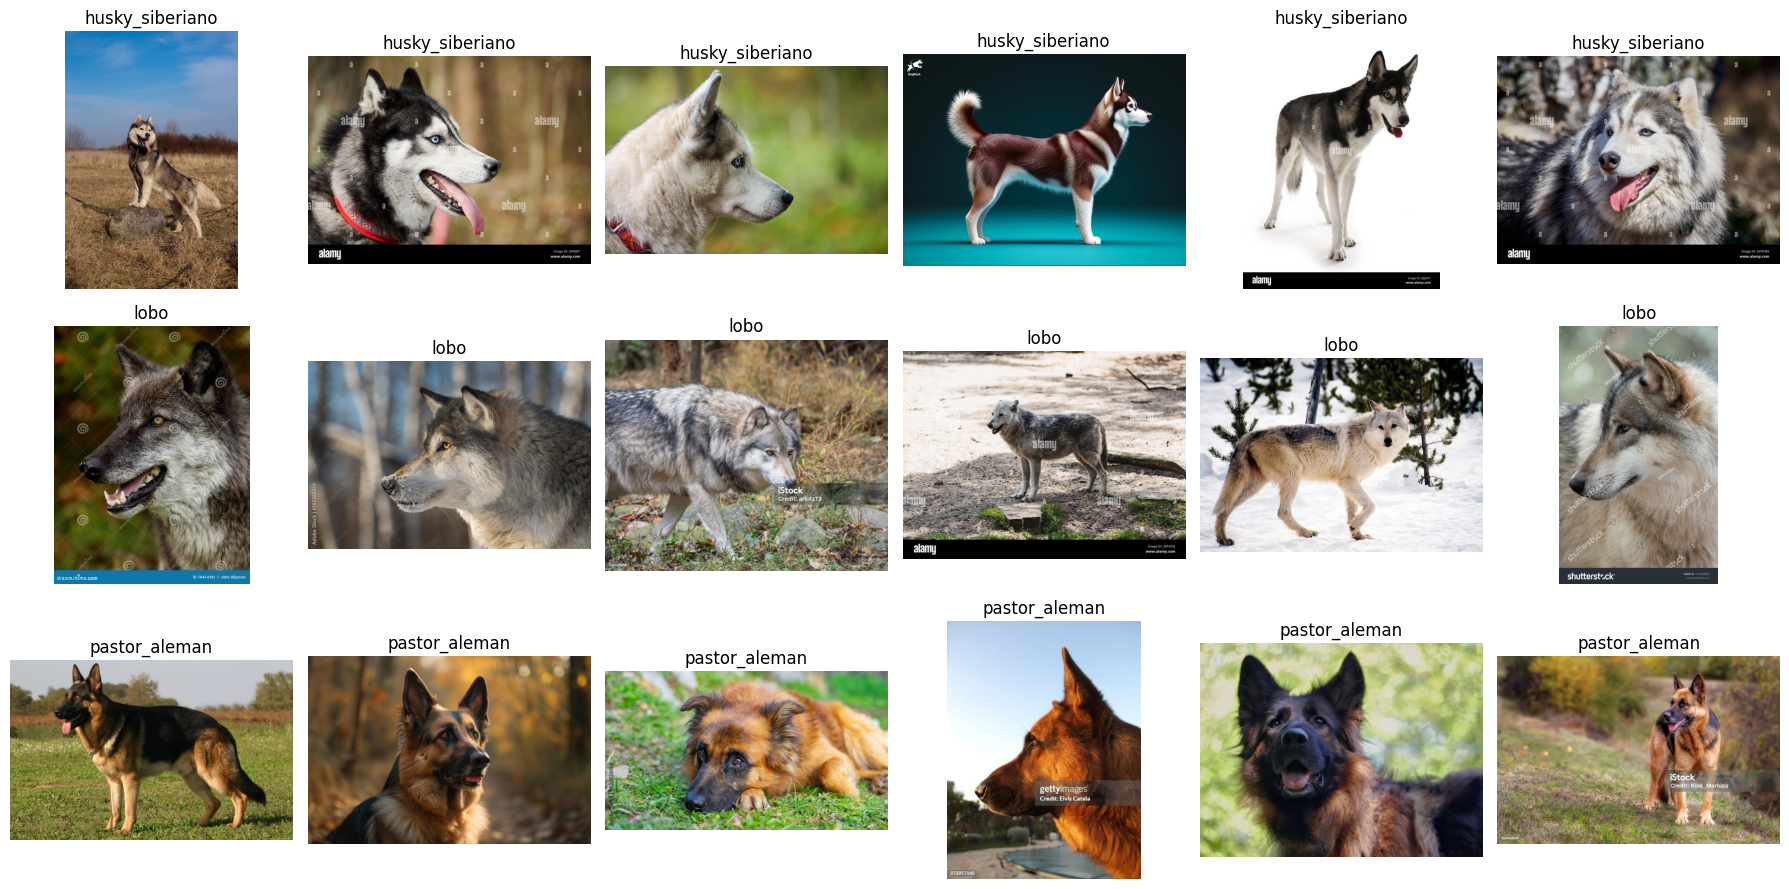

In [11]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Inspección con nombres de archivo y limpieza manual

`show_random_images` no muestra el nombre del archivo. `show_class` sí, para poder
eliminar imágenes concretas. Criterio de limpieza: cachorros, fotos con clases
mezcladas, ilustraciones, sujetos muy pequeños e imágenes dudosas (por ejemplo,
posible coyote o híbrido en `lobo`).

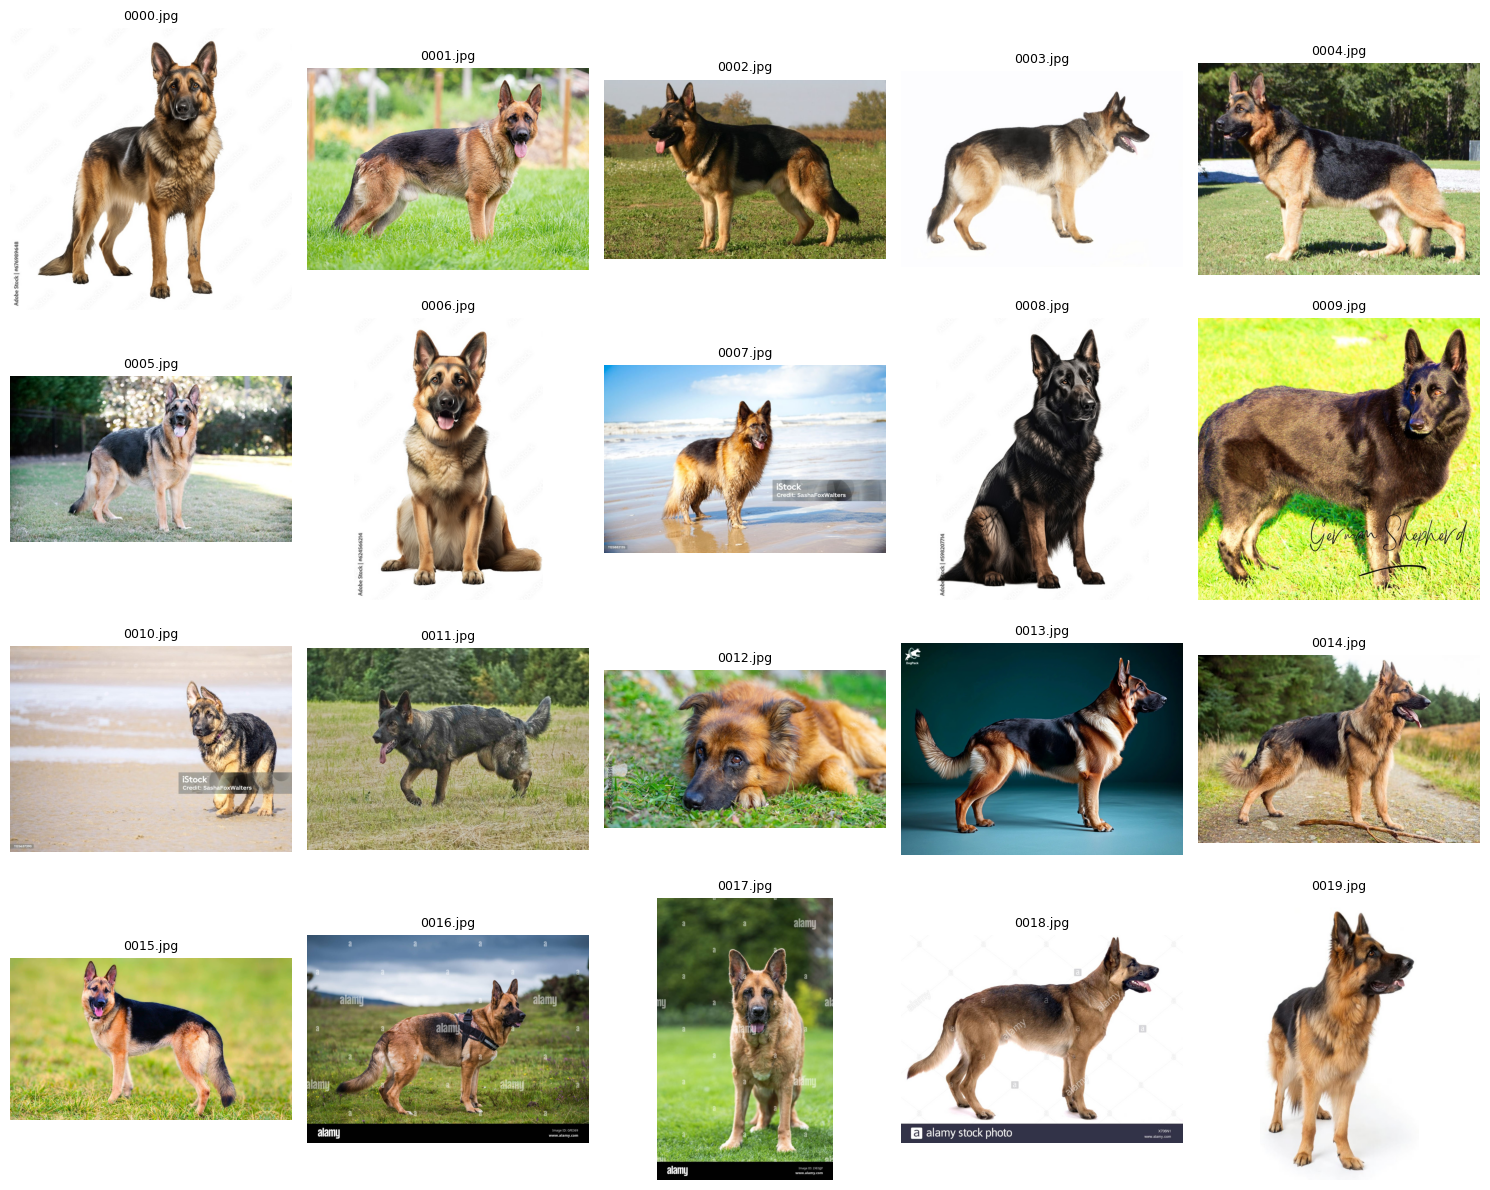

In [12]:
def show_class(class_name, start=0, n=20, cols=5):
    files = sorted((RAW_DIR / class_name).glob("*.jpg"))[start:start+n]
    rows = max(1, -(-len(files) // cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
    axes = np.array(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, f in zip(axes, files):
        ax.imshow(Image.open(f))
        ax.set_title(f.name, fontsize=9)
    plt.tight_layout()

# Revisar cada clase por bloques: start=0, 20, 40, ...
show_class("pastor_aleman", start=0)

### Casi duplicados

El hash SHA-256 elimina duplicados exactos. Durante la descarga también se usa un hash perceptual **conservador** para no almacenar copias casi idénticas dentro de la misma clase.

Después de terminar las descargas, `find_near_duplicates` permite una revisión más amplia del dataset. Este detector puede producir falsos positivos, por lo que **los candidatos de esta etapa se revisan visualmente antes de borrar una imagen ya almacenada**.


Pares candidatos para revisión: 3
4 husky_siberiano/0043.jpg husky_siberiano/0093.jpg
4 lobo/0029.jpg lobo/0073.jpg
4 lobo/0073.jpg lobo/0125.jpg


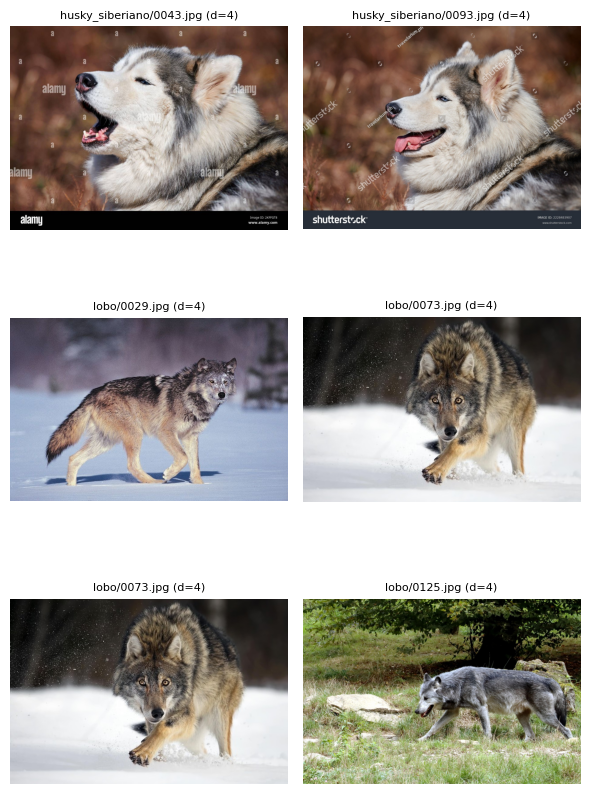

In [15]:
def ahash(path, size=8):
    img = Image.open(path).convert("L").resize((size, size))
    a = np.asarray(img, dtype=np.float32)
    return (a > a.mean()).flatten()


def find_near_duplicates(root, max_dist=4):
    items = [(p, ahash(p)) for p in sorted(Path(root).rglob("*.jpg"))]
    pairs = []
    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            # Solo comparamos dentro de la misma clase para evitar marcar
            # dos imágenes visualmente parecidas de clases distintas.
            if items[i][0].parent.name != items[j][0].parent.name:
                continue
            d = int(np.sum(items[i][1] != items[j][1]))
            if d <= max_dist:
                pairs.append((d, items[i][0], items[j][0]))
    return sorted(pairs, key=lambda x: x[0])


def show_pairs(pairs, max_pairs=6):
    pairs = pairs[:max_pairs]
    if not pairs:
        print("Sin casi duplicados con el umbral actual.")
        return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(6, 3 * len(pairs)))
    axes = np.atleast_2d(axes)
    for row, (d, a, b) in enumerate(pairs):
        for col, p in enumerate((a, b)):
            axes[row, col].imshow(Image.open(p))
            axes[row, col].set_title(f"{p.parent.name}/{p.name} (d={d})", fontsize=8)
            axes[row, col].axis("off")
    plt.tight_layout()

near_pairs = find_near_duplicates(RAW_DIR)
print("Pares candidatos para revisión:", len(near_pairs))
for d, a, b in near_pairs[:30]:
    print(d, a.parent.name + "/" + a.name, b.parent.name + "/" + b.name)
show_pairs(near_pairs)


In [14]:
# Limpieza semántica manual
# Completa esta lista SOLO después de revisar las imágenes con show_class().
# Los archivos de esta lista sí se eliminan de data_raw porque se determinó
# visualmente que no sirven para el problema.
to_delete = [
    # ("clase", "archivo.jpg"),
]

for cls, name in to_delete:
    path = RAW_DIR / cls / name
    path.unlink(missing_ok=True)

print("Eliminadas manualmente en esta ronda:", len(to_delete))
dataset_status(RAW_DIR)


Eliminadas manualmente en esta ronda: 0
Conteo actual:
  lobo: 150 -> OK
  husky_siberiano: 150 -> OK
  pastor_aleman: 150 -> OK


{'husky_siberiano': 150, 'lobo': 150, 'pastor_aleman': 150}

### Depuración final antes del split

Antes de continuar, el dataset debe estar definitivamente limpio.

- Los duplicados exactos se eliminan automáticamente durante la descarga.
- Los casi duplicados muy cercanos se rechazan automáticamente durante la descarga con un umbral conservador.
- Los candidatos adicionales de casi duplicados se muestran para revisión visual.
- La calidad semántica (clase correcta, dibujos/logos, texto, imágenes ambiguas, fondos correlacionados, etc.) requiere inspección visual.
- Los archivos rechazados **no se almacenan**; el proceso conserva solo el dataset útil y contadores de descarte.

**Importante:** cualquier cambio en `data_raw` obliga a ejecutar de nuevo el split 70/15/15 y todo el entrenamiento posterior. Los resultados de `test` obtenidos antes de la limpieza final no deben reutilizarse.

Antes del split ejecuta:
1. `dataset_status(RAW_DIR)`;
2. la inspección visual final;
3. `split_dataset(RAW_DIR, SPLIT_DIR)`;
4. las celdas de `image_dataset_from_directory`;
5. el entrenamiento y las evaluaciones posteriores.


### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

**Registro del checkpoint (hallazgos de la inspección):**

- **Conteo:** se registra automáticamente con `dataset_status(RAW_DIR)` después de cada ronda.
- **Duplicados exactos:** se eliminan automáticamente mediante SHA-256 y no se conservan las imágenes rechazadas.
- **Casi duplicados:** se filtran de forma conservadora durante la descarga y se pueden revisar con `find_near_duplicates`.
- **Marcas de agua:** no se eliminan automáticamente por el solo hecho de existir; se consideran problemáticas si introducen una señal artificial o una diferencia sistemática entre clases.
- **Cachorros:** no se eliminan automáticamente; solo se descartan si son ambiguos, están mal etiquetados o generan un problema claro para el objetivo del dataset.
- **Dibujos/logos/diagramas:** se eliminan durante la inspección semántica cuando no representan fotografías adecuadas para el problema.
- **Fondos:** se revisan para evitar que el modelo aprenda el fondo en lugar del animal.
- **Fotos con varios animales:** se aceptan si la clase es inequívoca; se eliminan las que mezclen clases o sean ambiguas.

Completa en la entrega el número final de imágenes por clase y el problema de calidad más frecuente encontrado.


In [16]:
# Resumen reproducible de la construcción y limpieza del dataset
final_counts = dataset_status(RAW_DIR)
print("\nResumen final antes del split:")
print("Total de imágenes útiles:", sum(final_counts.values()))
print("Objetivo por clase:", f"{MIN_IMAGES_PER_CLASS}–{MAX_IMAGES_PER_CLASS}")

assert len(final_counts) == 3, "Deben existir exactamente 3 clases."

if not all(n >= MIN_IMAGES_PER_CLASS for n in final_counts.values()):
    faltantes = {
        cls: max(0, MIN_IMAGES_PER_CLASS - final_counts.get(cls, 0))
        for cls in SEARCHES
    }
    print("\n⚠️ Dataset todavía insuficiente.")
    print("Imágenes que faltan para llegar al mínimo:", faltantes)
    print("Realiza otra ronda con términos de búsqueda nuevos antes del split.")
    raise RuntimeError(
        "No se puede continuar al split: alguna clase está por debajo de 100 imágenes útiles."
    )


Conteo actual:
  lobo: 150 -> OK
  husky_siberiano: 150 -> OK
  pastor_aleman: 150 -> OK

Resumen final antes del split:
Total de imágenes útiles: 450
Objetivo por clase: 100–150


# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

> **Orden obligatorio:** ejecutar esta sección **después** de terminar toda la descarga y limpieza de `data_raw`.
>
> `split_dataset` copia los archivos actuales de `data_raw`. Si se modifica `data_raw` después del split, vuelve a ejecutar esta celda y las celdas posteriores de carga/entrenamiento para no conservar datos antiguos.


In [17]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'husky_siberiano': 105, 'lobo': 105, 'pastor_aleman': 105}
validation {'husky_siberiano': 22, 'lobo': 22, 'pastor_aleman': 22}
test {'husky_siberiano': 23, 'lobo': 23, 'pastor_aleman': 23}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

### Respuesta — contaminación del conjunto de prueba

El conjunto de prueba debe mantenerse independiente hasta la evaluación final. Si se utiliza repetidamente para decidir el número de épocas, el `learning_rate` o cuántas capas descongelar, esas decisiones empiezan a adaptarse indirectamente a los ejemplos del test. Esto produce una estimación de desempeño optimista y hace que el test deje de representar una evaluación verdaderamente independiente. Por ello, en este trabajo las decisiones de entrenamiento y fine-tuning se toman con `train` y `validation`, y `test` se utiliza para comparar el modelo antes y después del ajuste final.


# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [18]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 315 files belonging to 3 classes.
Found 66 files belonging to 3 classes.
Found 69 files belonging to 3 classes.
['husky_siberiano', 'lobo', 'pastor_aleman']


### Pesos por clase

Las clases quedan con distinto número de imágenes de entrenamiento. `class_weight` pondera la
pérdida de cada clase de forma inversamente proporcional a su frecuencia en `train`, de modo que
la clase mayoritaria no domine el aprendizaje. Solo afecta al entrenamiento, no a la validación ni al test.

In [19]:
train_counts = count_images(SPLIT_DIR / "train")
total_train = sum(train_counts.values())

class_weight = {
    i: total_train / (NUM_CLASSES * train_counts[name])
    for i, name in enumerate(class_names)
}

print(train_counts)
print({class_names[i]: round(w, 3) for i, w in class_weight.items()})

{'husky_siberiano': 105, 'lobo': 105, 'pastor_aleman': 105}
{'husky_siberiano': 1.0, 'lobo': 1.0, 'pastor_aleman': 1.0}


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [20]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

In [21]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
    class_weight=class_weight,   # compensa el desbalance entre clases (ver celda anterior)
)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 58s 5s/step - accuracy: 0.6127 - loss: 0.9114 - val_accuracy: 0.9697 - val_loss: 0.5340
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.9302 - loss: 0.4550 - val_accuracy: 0.9848 - val_loss: 0.2720
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.9841 - loss: 0.2568 - val_accuracy: 0.9848 - val_loss: 0.1656
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.9778 - loss: 0.1852 - val_accuracy: 0.9848 - val_loss: 0.1146
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.9905 - loss: 0.1421 - val_accuracy: 0.9848 - val_loss: 0.0886
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.9905 - loss: 0.1222 - val_accuracy: 0.9848 - val_loss: 0.0744
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.9873 - loss: 0.0962 - val_accuracy: 0.9848 - val_loss: 0.0642
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.9873 - loss: 0.0854 - val_accuracy: 0.9848 - val_loss:

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

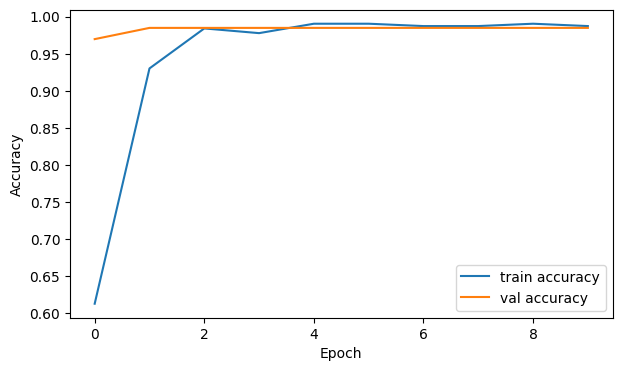

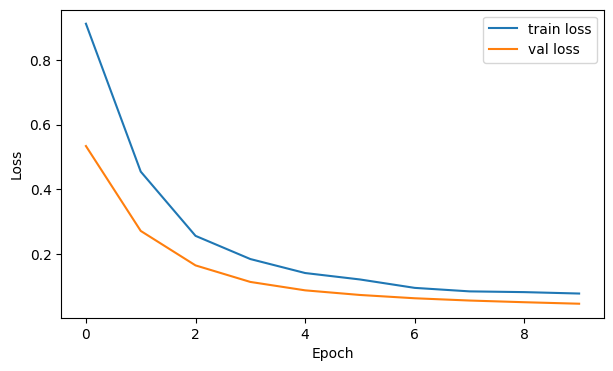

In [22]:
# Completa las cuatro curvas usando el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [23]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 1.0000


                 precision    recall  f1-score   support

husky_siberiano      1.000     1.000     1.000        23
           lobo      1.000     1.000     1.000        23
  pastor_aleman      1.000     1.000     1.000        23

       accuracy                          1.000        69
      macro avg      1.000     1.000     1.000        69
   weighted avg      1.000     1.000     1.000        69



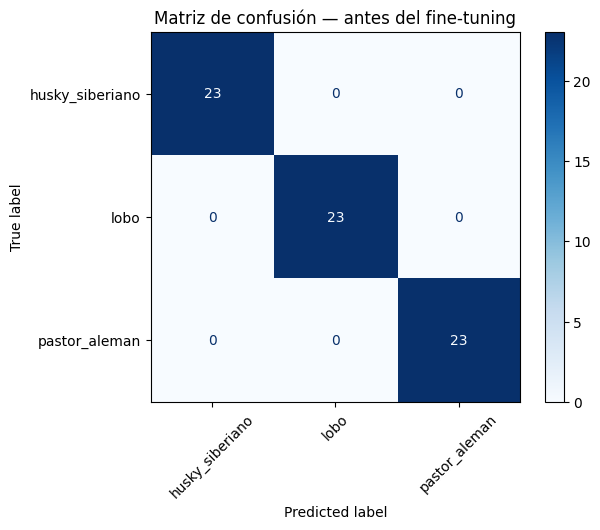

In [24]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

### Respuestas — TODO 4

**1. ¿Cuál clase obtuvo mejores resultados?**

Las tres clases obtuvieron exactamente el mismo resultado en el conjunto de prueba: `precision = 1.000`, `recall = 1.000` y `F1 = 1.000`. Por tanto, ninguna clase fue superior a las demás.

**2. ¿Cuál fue la principal confusión?**

No hubo una confusión entre clases. La matriz de confusión contiene 23 aciertos para cada clase y cero errores.

**3. ¿La accuracy global oculta algún problema por clase?**

En esta ejecución no se observa un problema oculto por clase: las tres clases tienen los mismos valores de precision, recall y F1. Aun así, una accuracy del 100 % sobre un conjunto de prueba de 69 imágenes no demuestra por sí sola una generalización perfecta; la diversidad y calidad del dataset siguen siendo importantes.

**4. ¿Qué cambiarías primero en el dataset antes de cambiar el modelo?**

Priorizaría aumentar la diversidad del dataset y reducir posibles señales accidentales: diferentes fondos, poses, iluminación y contextos, además de continuar revisando duplicados o casi duplicados y elementos visuales como marcas de agua. Esto ayuda a comprobar que el modelo aprende características de los animales y no pistas específicas de las imágenes descargadas.


# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [25]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

### Justificación de la decisión de fine-tuning

Se eligieron las **20 capas finales** de EfficientNetB0 como punto de partida, siguiendo la recomendación del taller. Se mantuvieron congeladas las capas `BatchNormalization` para evitar actualizar sus estadísticas con un dataset relativamente pequeño. En la fase inicial, la `val_accuracy` llegó rápidamente a aproximadamente 0.9848 y se mantuvo estable mientras `val_loss` continuó disminuyendo; por ello no había evidencia de validación que justificara descongelar una porción mucho mayor del backbone.

El resultado real fue **15 capas de la base efectivamente entrenables de 238**, porque algunas de las últimas 20 capas son `BatchNormalization` y permanecieron congeladas.


In [26]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 1e-5
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)

Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 66s 5s/step - accuracy: 1.0000 - loss: 0.0583 - val_accuracy: 0.9848 - val_loss: 0.0421
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.9937 - loss: 0.0645 - val_accuracy: 0.9848 - val_loss: 0.0371
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 1.0000 - loss: 0.0475 - val_accuracy: 0.9848 - val_loss: 0.0343
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 50s 5s/step - accuracy: 0.9968 - loss: 0.0487 - val_accuracy: 0.9848 - val_loss: 0.0326
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 42s 4s/step - accuracy: 0.9937 - loss: 0.0508 - val_accuracy: 0.9848 - val_loss: 0.0315


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

### Interpretación de la comparación

Los resultados obtenidos fueron:

- **Antes del fine-tuning:** accuracy de test = `1.0000`.
- **Después del fine-tuning:** accuracy de test = `1.0000`.
- **Diferencia:** `+0.0000`.

Por tanto, el fine-tuning **no mejoró la accuracy observable en el conjunto de prueba**, porque el modelo ya clasificaba correctamente todas las imágenes del test antes del ajuste. Sin embargo, durante el fine-tuning la pérdida de validación siguió disminuyendo, hasta aproximadamente `0.0315`, mientras la `val_accuracy` permaneció en `0.9848`. Esto indica que el ajuste siguió refinando el modelo en validación, pero no produjo una mejora medible en la clasificación del test.


In [27]:
# Comparación final: el baseline debe existir antes del fine-tuning.
if "test_acc_before" not in globals():
    raise RuntimeError(
        "No existe test_acc_before. Ejecuta primero la evaluación del modelo congelado "
        "y guarda su accuracy antes de hacer fine-tuning."
    )

test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")


Antes del fine-tuning  : 1.0000
Después del fine-tuning: 1.0000
Diferencia              : +0.0000


                 precision    recall  f1-score   support

husky_siberiano      1.000     1.000     1.000        23
           lobo      1.000     1.000     1.000        23
  pastor_aleman      1.000     1.000     1.000        23

       accuracy                          1.000        69
      macro avg      1.000     1.000     1.000        69
   weighted avg      1.000     1.000     1.000        69



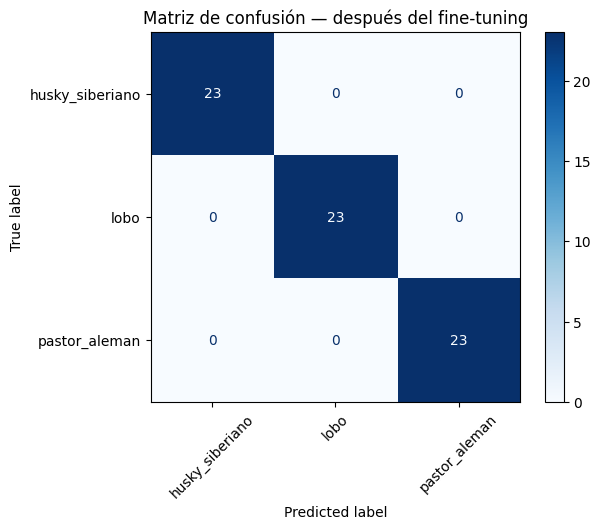

In [28]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

In [29]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

No se encontraron errores en este conjunto.


### Resultado real del análisis de errores

La función de análisis se ejecutó sobre el conjunto de prueba y produjo:

> `No se encontraron errores en este conjunto.`

Esto coincide con la matriz de confusión: las 69 imágenes del test fueron clasificadas correctamente. Por tanto, **no es metodológicamente correcto inventar cinco errores** para llenar la tabla solicitada por el taller.

El requisito de seleccionar al menos cinco errores no puede cumplirse literalmente con esta ejecución porque no existen cinco errores reales que analizar. La documentación final debe conservar este resultado tal como ocurrió. Si el profesor exige obligatoriamente cinco casos, la alternativa correcta sería utilizar otro conjunto de evaluación o ejemplos externos/difíciles y etiquetarlos explícitamente como *casos difíciles* o *errores en evaluación externa*, nunca como errores del test actual.


## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

### Conclusiones — TODO 6

**1. ¿Qué aprendiste al construir el dataset?**

La construcción del dataset mostró que obtener muchas imágenes no es suficiente: es necesario revisar etiquetas, calidad técnica, duplicados, casi duplicados, marcas de agua, fondos, dibujos/logos y posibles señales que permitan al modelo aprender patrones accidentales. También fue necesario realizar una segunda ronda de búsquedas para alcanzar 150 imágenes útiles por clase.

**2. ¿Cuál fue el principal problema de calidad?**

Entre los problemas observados estuvieron la presencia de imágenes con marcas de agua y la aparición de imágenes duplicadas o muy similares. También fue necesario revisar visualmente los casos detectados por el hash perceptual. No se estableció un conteo formal que permita afirmar que uno de estos problemas fue numéricamente el más frecuente, por lo que no se debe presentar esa afirmación como un dato medido.

**3. ¿Cuánto cambió el desempeño después del fine-tuning?**

La accuracy de test pasó de `1.0000` a `1.0000`, por lo que el cambio fue de `0.0000` puntos de accuracy.

**4. ¿El fine-tuning ayudó? ¿Por qué?**

No produjo una mejora observable en la accuracy del test, porque el modelo ya alcanzaba 100 %. Sí produjo una reducción adicional de la pérdida de validación, pero no cambió ninguna predicción del conjunto de prueba. Por ello, no puede afirmarse que haya mejorado la capacidad de clasificación medida por test en esta ejecución.

**5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?**

Mejoraría primero los **datos**: aumentar su diversidad, incorporar condiciones visuales más variadas y continuar controlando duplicados, fondos y señales artificiales. Antes de cambiar la arquitectura tendría más sentido comprobar la generalización con datos nuevos o externos, ya que el modelo actual ya alcanza 100 % sobre el test utilizado.


# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [ ]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

# 🏠 Cierre conceptual — ENTREGA

### Feature extraction / transfer learning con base congelada

Se utiliza una red previamente entrenada, en este caso EfficientNetB0 con pesos de ImageNet, como extractor de características. El backbone permanece congelado y sus parámetros no se actualizan. Los parámetros que se aprenden pertenecen principalmente a la nueva cabeza de clasificación (`GlobalAveragePooling2D`, `Dropout` y `Dense`), que se adapta a las tres clases del problema.

### Fine-tuning

Se parte de esos pesos previamente aprendidos, pero se permite actualizar una parte final del backbone para adaptar características de alto nivel al nuevo problema. En este trabajo se seleccionaron las últimas 20 capas como punto de partida, manteniendo congeladas las capas `BatchNormalization`, y se utilizó un `learning_rate` mucho menor (`1e-5`) para realizar ajustes pequeños sobre los pesos preentrenados.

### CNN entrenada desde cero

Una CNN entrenada desde cero no parte de pesos aprendidos en otro problema. Sus parámetros se inicializan sin el conocimiento previo de ImageNet y la red debe aprender desde los datos disponibles tanto las características visuales como la clasificación. Esto normalmente exige más datos y entrenamiento. En transfer learning se reutiliza conocimiento previamente aprendido y se adapta al nuevo conjunto de clases.


# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega — revisión documentada

### Evidencia del trabajo en clase
- [x] Problema y clases definidos.
- [x] Dataset construido y revisado.
- [x] Train / validation / test creados después de la limpieza final.
- [x] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [x] Evaluación sobre test.
- [x] Matriz de confusión.
- [x] Precision / recall / F1 interpretados.
- [x] Fine-tuning ejecutado.
- [x] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados — **no hubo errores reales en el conjunto de test; se documentó esta situación sin inventar ejemplos.**
- [x] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

> **Nota:** si se modifica `data_raw`, todos los resultados posteriores al split quedan obsoletos y deben volver a ejecutarse. Esta versión documentada **no modifica las celdas de código ni sus salidas ya obtenidas**; solamente agrega las respuestas y la interpretación de los resultados de esta ejecución.


# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |

# 📋 Auditoría final de esta ejecución

Esta versión conserva los resultados obtenidos durante la ejecución que se entregó para revisión. La documentación agregada se basa en esos resultados y no introduce nuevas ejecuciones ni nuevos valores.

**Dataset final:** 150 imágenes por clase, 450 imágenes en total.

**Split:** 315 train, 66 validation y 69 test; 23 imágenes de test por clase.

**Modelo inicial:** EfficientNetB0 con backbone congelado.

**Test antes del fine-tuning:** 100 %.

**Fine-tuning:** últimas 20 capas como punto de partida; 15 capas de la base quedaron efectivamente entrenables porque `BatchNormalization` permaneció congelada.

**Test después del fine-tuning:** 100 %.

**Cambio:** 0 puntos de accuracy.

**Errores en test:** 0.

**Casi duplicados detectados para revisión:** 3 pares; los tres fueron revisados manualmente y se decidió conservarlos.

**Criterio de documentación:** no se inventan errores, eliminaciones ni mejoras que no aparezcan en los resultados de esta ejecución.
